# CP2 experiments dashboard — read-only

Pulls every run that `generate_grids.ipynb` logged via `log_run()` into
`experiments/runs.jsonl` (+ the saved grid sets in `experiments/sets/`). **This notebook
recomputes nothing model-based**: every metric shown is the value measured at run time with
the live gate and recorded seeds. The only computation here is exact distance math on the
saved grids (and each loaded set is asserted to reproduce its logged diversity bit-for-bit,
proving the files match the ledger). No course data, no models, no GPU — opens in seconds.


In [6]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def _ps2_root(start):
    d = os.path.abspath(start)
    while not os.path.exists(os.path.join(d, "environment.yml")):
        parent = os.path.dirname(d)
        assert parent != d, "run this notebook from inside the ps2 repo"
        d = parent
    return d


PS2_ROOT = _ps2_root(os.getcwd())
LEDGER = os.path.join(PS2_ROOT, "experiments", "runs.jsonl")
JOEL = 0.7566

with open(LEDGER) as f:
    RECS = [json.loads(line) for line in f if line.strip()]
df = pd.json_normalize(RECS).sort_values("expected_score", ascending=False)
print(f"{len(df)} runs loaded from {os.path.relpath(LEDGER, PS2_ROOT)}")


6 runs loaded from experiments/runs.jsonl


## Leaderboard
Sorted by **expected score** (the honest scoreboard estimate), config beside metrics so
"what changed" and "what it did" sit together. `scoreboard` fills in as real tries come back.


In [7]:
config_cols = sorted(c for c in df.columns if c.startswith("config."))
cols = (["expected_score", "expected_sd", "diversity", "p_all_pass", "worst_margin",
         "mean_pass_prob", "scoreboard"] + config_cols + ["parent", "commit", "timestamp", "note"])
df.set_index("name")[[c for c in cols if c in df.columns]]


,expected_score,expected_sd,diversity,p_all_pass,worst_margin,mean_pass_prob,scoreboard,config.T0,config.anneal_seed,config.anneal_steps,...,config.safety_margin,config.spread_diversity,config.spread_seed,config.spread_steps,config.stage,config.teleport_every,parent,commit,timestamp,note
name,,,,,,,,,,,,,,,,,,,,,
e3_hotanneal1M_tp_m06,0.702070,0.012173,0.724061,0.042548,0.060073,0.969022,0.71,0.001,0.0,1000000.0,...,NaN,NaN,NaN,NaN,NaN,25000.0,e2_sp2M_b03_m06_g2,37d4a19+dirty,2026-11-08T11:58:07,hot-T anneal + teleports; v1 plateaued at 0.725
e2_sp2M_b03_m06_g3,0.699749,0.012584,0.725041,0.025108,0.060008,0.963928,NaN,NaN,0.0,500000.0,...,NaN,NaN,1.0,2000000.0,g3,NaN,e2_sp2M_b03_m06_g2,37d4a19+dirty,2026-11-08T11:02:12,joint soft anneal + straggler repair
g3_anneal500k_m06,0.699561,0.012358,0.724980,0.025210,0.060066,0.963979,NaN,NaN,0.0,500000.0,...,NaN,NaN,NaN,NaN,NaN,NaN,g2_spread200k_b01_m06,f235344+dirty,2026-11-08T10:23:10,"first full run; printed: diversity 0.7250, exp..."
e2_sp2M_b03_m06_safe0.1,0.685078,0.001066,0.685224,0.977424,0.100044,0.999772,NaN,NaN,0.0,500000.0,...,0.1,NaN,1.0,2000000.0,safety,NaN,e2_sp2M_b03_m06_g3,37d4a19+dirty,2026-11-08T11:02:59,post-anneal margin boost: fewer casualties for...
e2_sp2M_b03_m06_g2,0.671777,0.012104,0.695122,0.028465,0.060089,0.965152,NaN,NaN,0.0,500000.0,...,NaN,0.773551,1.0,2000000.0,g2,NaN,NaN,37d4a19+dirty,2026-11-08T10:51:26,repair of the spread set
g2_spread200k_b01_m06,0.666879,0.012143,0.691061,0.026154,0.060062,0.964331,NaN,NaN,NaN,NaN,...,NaN,NaN,1.0,200000.0,NaN,NaN,NaN,f235344+dirty,2026-11-08T10:23:10,"first full run; printed: diversity 0.6911, exp..."


## Expected vs raw diversity
The diagonal is "no casualties" — a run's horizontal distance from it is its expected-failure
drag. Up and right is better; past the dashed lines beats Joel's real 0.7566.


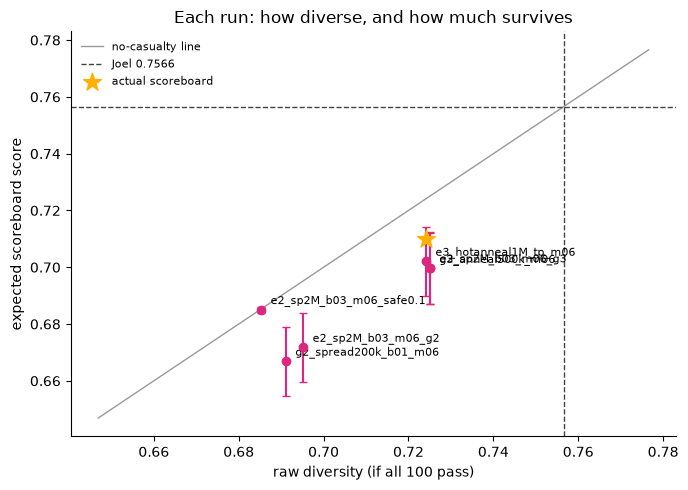

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
lo = min(df["expected_score"].min(), df["diversity"].min()) - 0.02
hi = max(df["diversity"].max(), JOEL) + 0.02
ax.plot([lo, hi], [lo, hi], color="#999999", linewidth=1, label="no-casualty line")
ax.axhline(JOEL, color="#444444", linewidth=1, linestyle="--", label=f"Joel {JOEL}")
ax.axvline(JOEL, color="#444444", linewidth=1, linestyle="--")
ax.errorbar(df["diversity"], df["expected_score"], yerr=df["expected_sd"],
            fmt="o", color="#DC267F", ecolor="#DC267F", capsize=3, zorder=3)
sb = df.dropna(subset=["scoreboard"])
if len(sb):
    ax.scatter(sb["diversity"], sb["scoreboard"], marker="*", s=180, color="#FFB000",
               zorder=4, label="actual scoreboard")
for _, r in df.iterrows():
    ax.annotate(r["name"], (r["diversity"], r["expected_score"]),
                textcoords="offset points", xytext=(7, 4), fontsize=8)
ax.set_xlabel("raw diversity (if all 100 pass)")
ax.set_ylabel("expected scoreboard score")
ax.set_title("Each run: how diverse, and how much survives")
ax.legend(frameon=False, fontsize=8)
ax.spines[["right", "top"]].set_visible(False)
plt.tight_layout()
plt.show()


## Diversity anatomy of the top runs
Per-grid mean 10-NN distance curves (the score is each curve's mean), computed exactly from the
saved sets. The assert proves each file reproduces its logged diversity — nothing drifted.


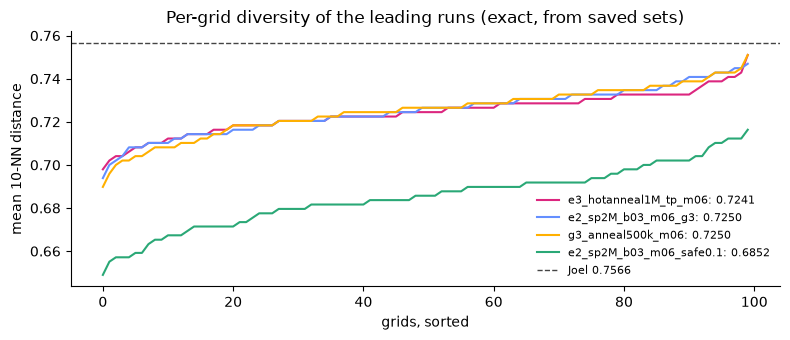

In [ ]:
def diversity_exact(gs, k=10, N=100):
    # verbatim math of the course's utils_public.diversity_score (kept local so this
    # notebook needs no course-repo bootstrap)
    from scipy.spatial.distance import pdist, squareform
    flat = np.reshape(gs, (len(gs), -1))
    D = squareform(pdist(flat, "hamming"))
    np.fill_diagonal(D, np.inf)
    kk = min(k, len(gs) - 1)
    return np.sort(D, axis=1)[:, :kk].mean(axis=1).sum() / N


def mean10_sorted(gs):
    from scipy.spatial.distance import pdist, squareform
    D = squareform(pdist(np.reshape(gs, (len(gs), -1)), "hamming"))
    np.fill_diagonal(D, np.inf)
    return np.sort(np.sort(D, axis=1)[:, :10].mean(axis=1))


show = pd.concat([df.head(4), df.dropna(subset=["scoreboard"])]).drop_duplicates("name")
colors = ["#DC267F", "#648FFF", "#FFB000", "#2AA876", "#785EF0", "#8C5A2B"]
fig, ax = plt.subplots(figsize=(8, 3.5))
for color, (_, r) in zip(colors, show.iterrows()):
    gs = np.load(os.path.join(PS2_ROOT, r["set_file"]))
    d = diversity_exact(gs)
    assert abs(d - r["diversity"]) < 1e-6, f"{r['name']}: file does not match ledger!"
    ax.plot(mean10_sorted(gs), color=color, label=f"{r['name']}: {d:.4f}")
ax.axhline(JOEL, color="#444444", linewidth=1, linestyle="--", label=f"Joel {JOEL}")
ax.set_xlabel("grids, sorted")
ax.set_ylabel("mean 10-NN distance")
ax.set_title("Per-grid diversity of the leading runs (exact, from saved sets)")
ax.legend(frameon=False, fontsize=8)
ax.spines[["right", "top"]].set_visible(False)
plt.tight_layout()
plt.show()


## Calibration verdict — actual vs expected
Fills in as scoreboard tries are logged with `log_scoreboard(name, actual)`. Points on the
diagonal = our expected score is honest; above = calibration pessimistic (trim margin);
below = optimistic (raise margin).


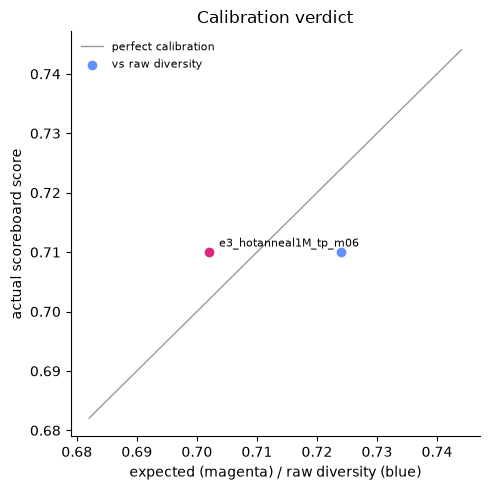

In [10]:
sb = df.dropna(subset=["scoreboard"])
if not len(sb):
    print("no scoreboard results logged yet - after a try, run "
          "log_scoreboard(name, actual) in generate_grids.ipynb")
else:
    fig, ax = plt.subplots(figsize=(5, 5))
    lo = min(sb["expected_score"].min(), sb["scoreboard"].min()) - 0.02
    hi = max(sb["diversity"].max(), sb["scoreboard"].max()) + 0.02
    ax.plot([lo, hi], [lo, hi], color="#999999", linewidth=1, label="perfect calibration")
    ax.scatter(sb["expected_score"], sb["scoreboard"], color="#DC267F", zorder=3)
    ax.scatter(sb["diversity"], sb["scoreboard"], color="#648FFF", zorder=3,
               label="vs raw diversity")
    for _, r in sb.iterrows():
        ax.annotate(r["name"], (r["expected_score"], r["scoreboard"]),
                    textcoords="offset points", xytext=(7, 4), fontsize=8)
    ax.set_xlabel("expected (magenta) / raw diversity (blue)")
    ax.set_ylabel("actual scoreboard score")
    ax.set_title("Calibration verdict")
    ax.legend(frameon=False, fontsize=8)
    ax.spines[["right", "top"]].set_visible(False)
    plt.tight_layout()
    plt.show()
